# Cell 1.0  //  Setup and Find the NASA File

In [1]:
import requests, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INK, PINK, MAUVE, BLUSH = "#3A1C2B", "#E8447A", "#8C6B76", "#FCE4EC"

OSD = "48"
meta = requests.get(f"https://osdr.nasa.gov/osdr/data/osd/files/{OSD}").json()

def find_files(obj):
    out = []
    if isinstance(obj, dict):
        if "file_name" in obj:
            out.append(obj)
        for v in obj.values():
            out += find_files(v)
    elif isinstance(obj, list):
        for v in obj:
            out += find_files(v)
    return out

files = find_files(meta)
dge_files = [f for f in files
             if "differential_expression" in f["file_name"].lower()
             and f["file_name"].lower().endswith(".csv")]
for i, f in enumerate(dge_files):
    print(i, f["file_name"])


0 GLDS-48_rna_seq_differential_expression_rRNArm_GLbulkRNAseq.csv
1 GLDS-48_rna_seq_differential_expression_GLbulkRNAseq.csv


# Cell 2  //  Load the Data

In [2]:
target = dge_files[0]
url = "https://osdr.nasa.gov" + target["remote_url"]
df = pd.read_csv(io.StringIO(requests.get(url).text))
print(df.shape)


(22877, 80)


# Cell 3  //  Space vs. Earth Comparison

In [3]:
fc_cols = [c for c in df.columns if c.startswith("Log2fc")]
p_cols = [c for c in df.columns if c.startswith("Adj.p")]

fc_col = next((c for c in fc_cols
               if "Space Flight" in c and "Ground Control" in c and "Carcass" in c),
              next(c for c in fc_cols if "Flight" in c and "Ground" in c))
comparison = fc_col.split("_", 1)[1]
p_col = next(c for c in p_cols if comparison in c)
gene_col = "SYMBOL" if "SYMBOL" in df.columns else df.columns[0]

first_group = comparison.split(")v(")[0]
flip = "Ground" in first_group
print("using:", fc_col)
print("flipping sign:", flip)

d = df[[gene_col, fc_col, p_col]].dropna().copy()
d.columns = ["gene", "fc", "padj"]
if flip:
    d["fc"] = -d["fc"]
d["neglog10p"] = -np.log10(d["padj"].clip(lower=1e-300))

up = d[(d["fc"] > 1) & (d["padj"] < 0.05)]
down = d[(d["fc"] < -1) & (d["padj"] < 0.05)]
print(f"genes up in space: {len(up)} | genes down in space: {len(down)}")


using: Log2fc_(Ground Control & Carcass)v(Space Flight & Carcass)
flipping sign: True
genes up in space: 112 | genes down in space: 72


# Cell 4  //  Sanity Check

In [4]:
mean_cols = [c for c in df.columns if c.startswith("Group.Mean") and "Carcass" in c]
check = df.set_index(gene_col).loc[:, mean_cols]
print("npas2 should be higher in space:")
print(check.loc[["Npas2"]].T)


npas2 should be higher in space:
SYMBOL                                      Npas2
Group.Mean_(Ground Control & Carcass)   23.389150
Group.Mean_(Space Flight & Carcass)    326.395188


# Cell 5  //  The Volcano Plot

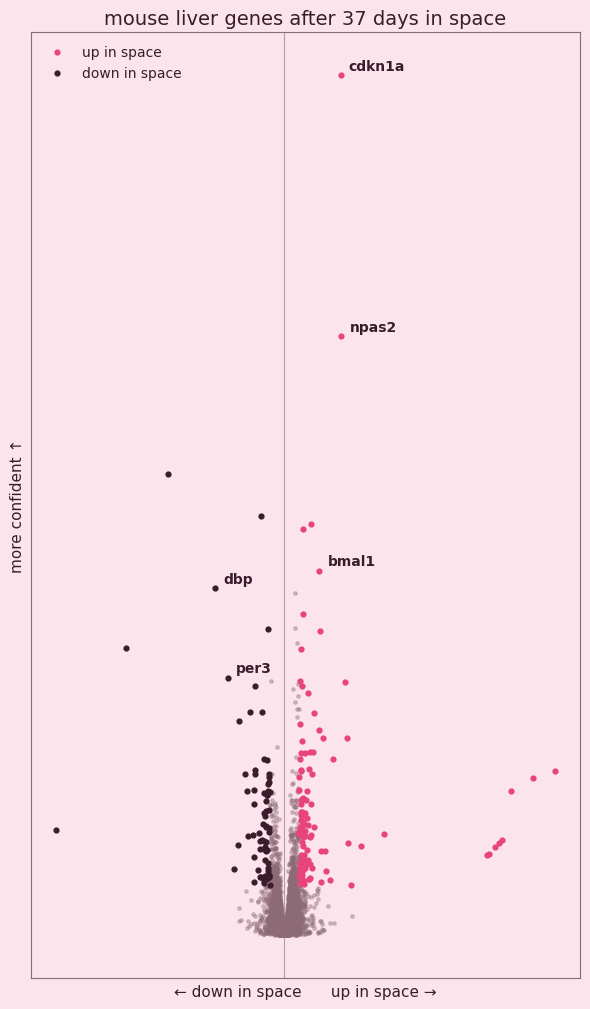

In [5]:
label_genes = ["Npas2", "Bmal1", "Dbp", "Per3", "Cdkn1a"]

fig, ax = plt.subplots(figsize=(6, 10.7), facecolor=BLUSH)
ax.set_facecolor(BLUSH)
ax.scatter(d["fc"], d["neglog10p"], s=6, c=MAUVE, alpha=0.35)
ax.scatter(up["fc"], up["neglog10p"], s=12, c=PINK, label="up in space")
ax.scatter(down["fc"], down["neglog10p"], s=12, c=INK, label="down in space")

for g in label_genes:
    row = d[d["gene"] == g]
    if row.empty:
        continue
    r = row.iloc[0]
    ax.annotate(g.lower(), (r["fc"], r["neglog10p"]), fontsize=10, color=INK,
                fontweight="bold", xytext=(6, 4), textcoords="offset points")

ax.axvline(0, color=MAUVE, lw=0.8, alpha=0.6)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("mouse liver genes after 37 days in space", color=INK, fontsize=14)
ax.set_xlabel("← down in space      up in space →", color=INK, fontsize=11)
ax.set_ylabel("more confident ↑", color=INK, fontsize=11)
ax.legend(frameon=False, labelcolor=INK, loc="upper left")
for s in ax.spines.values():
    s.set_color(MAUVE)

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.savefig("volcano.png", dpi=200, facecolor=BLUSH)
plt.show()


# Cell 6  //  The Body Clock Chart

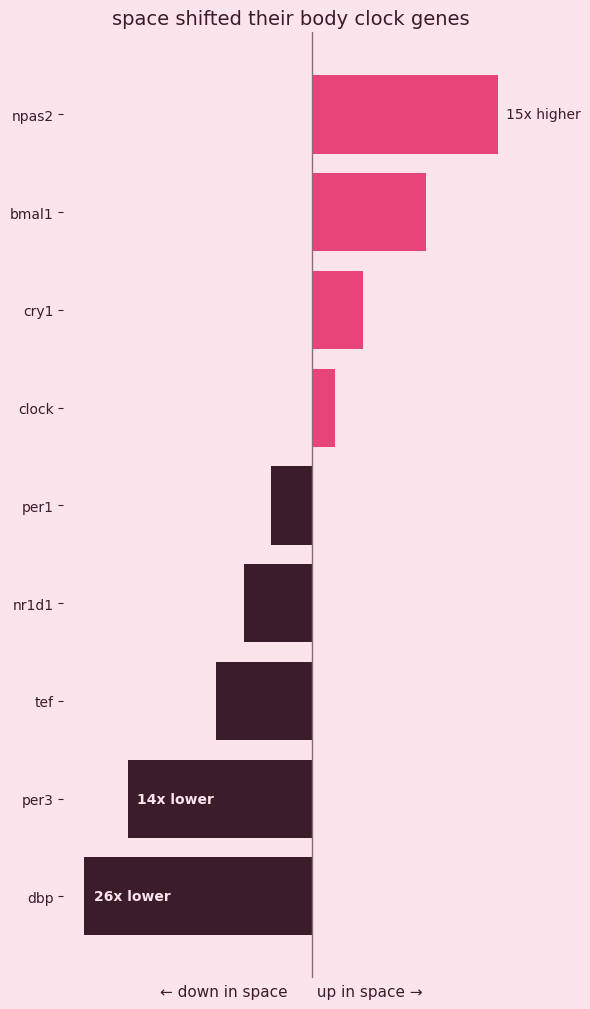

In [6]:
clock_show = ["Npas2", "Bmal1", "Cry1", "Clock", "Per1", "Nr1d1", "Tef", "Per3", "Dbp"]
c = d[d["gene"].isin(clock_show)].sort_values("fc")

fig, ax = plt.subplots(figsize=(6, 10.7), facecolor=BLUSH)
ax.set_facecolor(BLUSH)
ax.barh(c["gene"].str.lower(), c["fc"], color=[PINK if v > 0 else INK for v in c["fc"]])
ax.axvline(0, color=MAUVE, lw=1)
ax.tick_params(colors=INK)
ax.set_xticks([])
ax.set_title("space shifted their body clock genes", color=INK, fontsize=14)
ax.set_xlabel("← down in space      up in space →", color=INK, fontsize=11)
for s in ax.spines.values():
    s.set_visible(False)

for gene, label in [("Dbp", "26x lower"), ("Per3", "14x lower"), ("Npas2", "15x higher")]:
    r = c[c["gene"] == gene].iloc[0]
    y = list(c["gene"]).index(gene)
    if r["fc"] > 0:
        ax.text(r["fc"] + 0.15, y, label, va="center", ha="left", color=INK, fontsize=10)
    else:
        ax.text(r["fc"] + 0.2, y, label, va="center", ha="left", color=BLUSH, fontsize=10, fontweight="bold")

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.savefig("clock_genes.png", dpi=200, facecolor=BLUSH)
plt.show()


# Cell 7  //  All the Numbers

In [7]:
def times(fc):
    return f"{2 ** abs(fc):.1f}x"

print("=== totals ===")
print(f"genes tested: {len(d)}")
print(f"up in space: {len(up)}")
print(f"down in space: {len(down)}")
print(f"total changed: {len(up) + len(down)}")

print("\n=== body clock genes ===")
clock = ["Npas2", "Bmal1", "Dbp", "Per1", "Per2", "Per3", "Clock",
         "Cry1", "Cry2", "Nr1d1", "Nr1d2", "Tef", "Hlf"]
for g in clock:
    row = d[d["gene"] == g]
    if row.empty:
        continue
    r = row.iloc[0]
    direction = "up" if r["fc"] > 0 else "down"
    sig = "significant" if r["padj"] < 0.05 else "not significant"
    print(f"{g:<7} {direction} {times(r['fc'])}   padj={r['padj']:.2e}   ({sig})")


=== totals ===
genes tested: 13263
up in space: 112
down in space: 72
total changed: 184

=== body clock genes ===
Npas2   up 14.6x   padj=2.75e-16   (significant)
Bmal1   up 5.2x   padj=3.43e-10   (significant)
Dbp     down 26.4x   padj=9.64e-10   (significant)
Per1    down 1.8x   padj=3.76e-04   (significant)
Per2    down 1.8x   padj=4.35e-01   (not significant)
Per3    down 14.2x   padj=2.02e-07   (significant)
Clock   up 1.4x   padj=9.00e-03   (significant)
Cry1    up 2.1x   padj=1.80e-02   (significant)
Cry2    down 1.8x   padj=1.90e-03   (significant)
Nr1d1   down 2.7x   padj=3.61e-03   (significant)
Nr1d2   down 2.2x   padj=5.94e-03   (significant)
Tef     down 3.9x   padj=3.39e-07   (significant)
Hlf     down 1.6x   padj=1.21e-01   (not significant)
